In [1]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import RidgeCV, ElasticNetCV, HuberRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from sklearn.model_selection import train_test_split, KFold
from scipy.stats import spearmanr
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
)


c:\Users\marti\OneDrive\Desktop\EDHEC\M2 FENG\M2 - S1\Machine Learning\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#data = kagglehub.dataset_download("davidcariboo/player-scores")

In [3]:
clubs = pd.read_csv(".\\transfermarkt data\\clubs.csv")
transfer_panel = pd.read_csv(".\\transfermarkt data\\transfer_panel.csv", parse_dates=["date"])
cols_to_keep = ["club_id", "name", "domestic_competition_id", "squad_size", "average_age", "foreigners_percentage", "national_team_players", "net_transfer_record"]
transfer_full = transfer_panel.merge(clubs[cols_to_keep], left_on="from_club_id", right_on="club_id", how="left").merge(clubs[cols_to_keep], left_on="to_club_id", right_on="club_id", how="left", suffixes=("_from", "_to"))

In [4]:
transfer_full = transfer_full.sort_values(by=['player_id', 'date', 'num_prior_transfers']).reset_index(drop=True)
# 2. Grab the market value from the player's immediately preceding transfer
transfer_full['prev_market_value'] = transfer_full.groupby('player_id')['market_value_in_eur'].shift(1)

In [5]:
transfer_full=transfer_full[(transfer_full.transfer_fee > 0) & 
                            (transfer_full.transfer_fee.notna()) & 
                            (transfer_full.market_value_in_eur.notna())]

In [6]:
big5 = ["L1", "GB1", "IT1", "ES1", "FR1"]
comp_cols = ["domestic_competition_id_from", "domestic_competition_id_to"]
for col in comp_cols:
    transfer_full[col] = transfer_full[col].apply(lambda x: x if x in big5 else "Other")
transfer_full

,player_id,date,transfer_season,from_club_id,to_club_id,transfer_fee,market_value_in_eur,has_fee,num_prior_transfers,prev_transfer_fee,...,net_transfer_record_from,club_id_to,name_to,domestic_competition_id_to,squad_size_to,average_age_to,foreigners_percentage_to,national_team_players_to,net_transfer_record_to,prev_market_value
2,2989,2006-07-01,06/07,27,41,2500000.0,3000000.0,1,2,NaN,...,€-81.25m,41.0,Hamburger SV,L1,26.0,24.6,65.4,6.0,€-3.20m,NaN
3,2989,2012-07-15,12/13,41,199,3500000.0,6000000.0,1,3,2500000.0,...,€-3.20m,199.0,Sport Club Corinthians Paulista,Other,34.0,27.2,20.6,3.0,+€2.19m,3000000.0
8,3333,2008-08-29,08/09,762,405,15000000.0,8750000.0,1,3,7400000.0,...,+€93.00m,405.0,Aston Villa,GB1,29.0,27.4,72.4,16.0,+€31.50m,NaN
9,3333,2010-08-17,10/11,405,281,22000000.0,20000000.0,1,4,15000000.0,...,+€31.50m,281.0,Manchester City,GB1,32.0,25.2,62.5,22.0,€-152.03m,8750000.0
13,4391,2007-07-01,07/08,306,1090,3000000.0,800000.0,1,2,NaN,...,+-0,1090.0,AZ Alkmaar,Other,31.0,24.3,35.5,3.0,+€15.30m,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69523,1396595,2026-02-03,25/26,3268,141,6500000.0,1000000.0,1,2,NaN,...,+€700k,141.0,Galatasaray,Other,33.0,25.7,39.4,16.0,+€5.00m,100000.0
69543,1404902,2026-02-02,25/26,6772,75231,210000.0,125000.0,1,1,NaN,...,NaN,75231.0,Dinamo Makhachkala,Other,26.0,25.2,42.3,4.0,+€2.93m,200000.0
69598,1421433,2026-07-01,26/27,272,1237,28000000.0,500000.0,1,1,750000.0,...,+€1.98m,1237.0,Brighton & Hove Albion,GB1,37.0,25.0,78.4,19.0,€-8.70m,NaN
69630,1430854,2026-01-15,25/26,1014,504,240000.0,375000.0,1,1,NaN,...,NaN,504.0,Grasshopper Club Zurich,Other,30.0,23.7,53.3,2.0,+-0,NaN


In [7]:
def parse_to_int(val):
    if pd.isna(val):
        return np.nan
    
    # Clean string
    val = str(val).replace('€', '').strip()
    if val in ['-', '+-0', '0', '']:
        return 0
    
    # Apply multiplier based on suffix
    multiplier = 1
    if val.endswith('m'):
        multiplier = 1_000_000
        val = val[:-1]
    elif val.endswith('k'):
        multiplier = 1_000
        val = val[:-1]
        
    try:
        return int(round(float(val) * multiplier))
    except ValueError:
        return np.nan

In [8]:

# Convert column to nullable integer ('Int64')
transfer_full['net_transfer_record_from'] = (
    transfer_full['net_transfer_record_from']
    .apply(parse_to_int)
    .astype('Int64')
)


# Convert column to nullable integer ('Int64')
transfer_full['net_transfer_record_to'] = (
    transfer_full['net_transfer_record_to']
    .apply(parse_to_int)
    .astype('Int64')
)

transfer_full[["net_transfer_record_from", "net_transfer_record_to"]].head(10)

,net_transfer_record_from,net_transfer_record_to
2,-81250000,-3200000
3,-3200000,2190000
8,93000000,31500000
9,31500000,-152030000
13,0,15300000
18,-19500000,8200000
19,8200000,14000000
23,2500000,-103600000
24,-103600000,-81250000
25,-81250000,-54300000


In [9]:
transfer_full = pd.get_dummies(transfer_full, dtype="bool", columns=["position", "foot", "domestic_competition_id_to", "from_confederation", "to_confederation", "domestic_competition_id_from"])

In [10]:
transfer_full["spread"] = transfer_full.transfer_fee - transfer_full.market_value_in_eur
transfer_full["log_spread"] = np.log(transfer_full.transfer_fee / transfer_full.market_value_in_eur)
transfer_full["prev_spread"] = transfer_full.prev_transfer_fee - transfer_full.prev_market_value
transfer_full["prev_log_spread"] = np.log(transfer_full.prev_transfer_fee / transfer_full.prev_market_value)
transfer_full["new_club_bigger_squad"] = transfer_full["to_club_squad_size"] > transfer_full["from_club_squad_size"]
transfer_full["new_club_younger_squad"] = transfer_full["to_club_average_age"] < transfer_full["from_club_average_age"]
transfer_full["new_club_more_foreigners"] = transfer_full["to_club_foreigners_pct"] > transfer_full["from_club_foreigners_pct"]
transfer_full["new_club_more_national_team_players"] = transfer_full["to_club_national_team_players"] > transfer_full["from_club_national_team_players"]
transfer_full["log_curr_market_value"] = np.log(transfer_full.market_value_in_eur)
transfer_full["value_momentum"] = np.log(transfer_full.market_value_in_eur / transfer_full.prev_market_value)
transfer_full["curr_val_vs_fee_paid"] = np.log(transfer_full.market_value_in_eur / transfer_full.prev_transfer_fee)


correl = transfer_full[transfer_full.has_fee == 1].select_dtypes(exclude=["str"]).drop(columns=["date", 
                                                                                                "player_id",
                                                                                                "has_fee",
                                                                                                "has_recent_appearances", 
                                                                                                "from_club_id", 
                                                                                                "to_club_id", 
                                                                                                "club_id_to", 
                                                                                                "club_id_from", 
                                                                                                "squad_size_from",
                                                                                                "foreigners_percentage_from",
                                                                                                "national_team_players_from",
                                                                                                "squad_size_to",
                                                                                                "average_age_to",
                                                                                                "foreigners_percentage_to",
                                                                                                "national_team_players_to",
                                                                                                "average_age_from",
                                                                                                "transfer_fee",
                                                                                                "market_value_in_eur",
                                                                                                "to_club_squad_size",
                                                                                                "from_club_squad_size",
                                                                                                "to_club_average_age",
                                                                                                "from_club_average_age",
                                                                                                "to_club_foreigners_pct",
                                                                                                "from_club_foreigners_pct",
                                                                                                "to_club_national_team_players",
                                                                                                "from_club_national_team_players"]).corr()

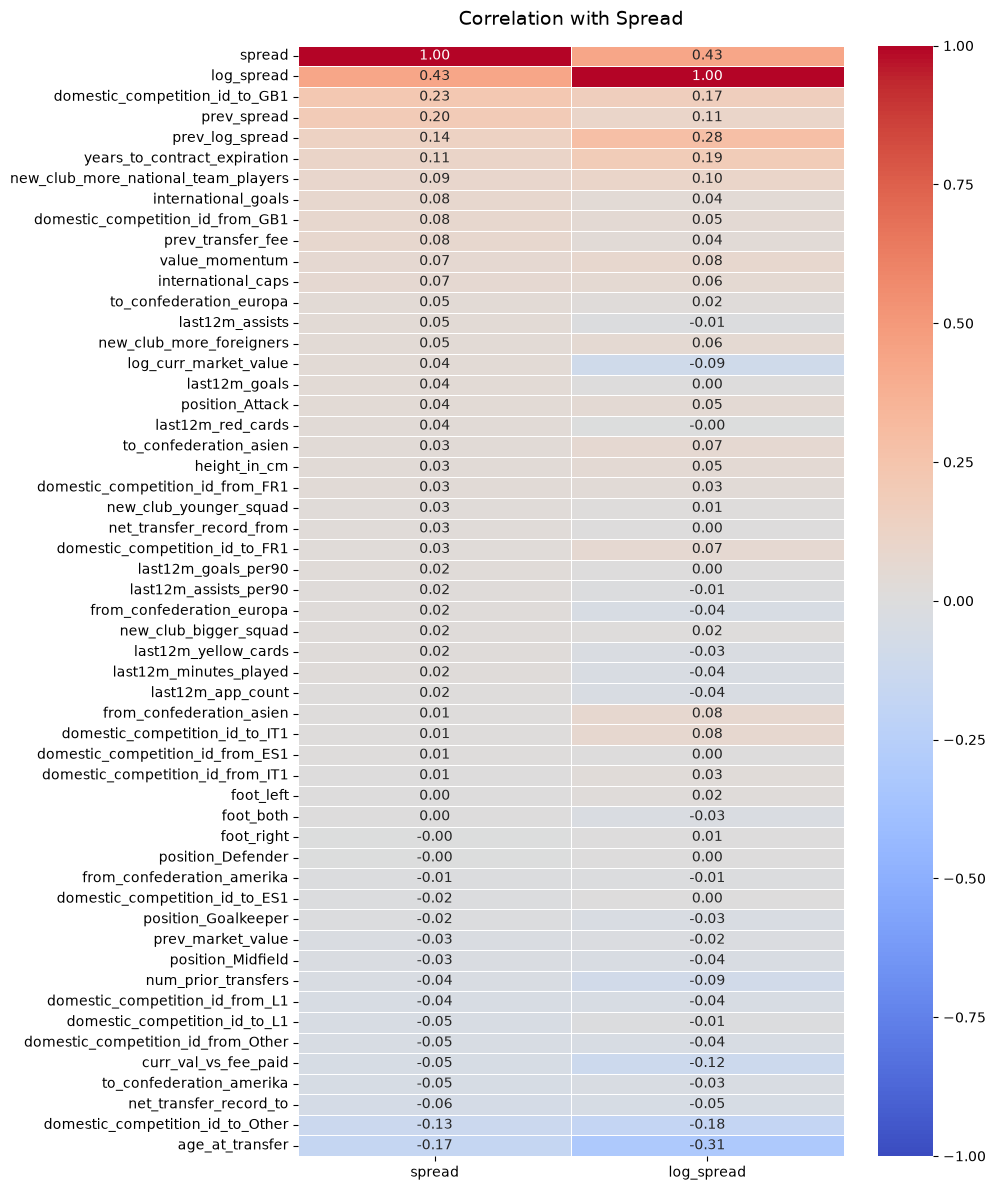

In [11]:
spread_corr = correl[['spread', "log_spread"]].sort_values(by='spread', ascending=False)

# 2. Plot as a tall, narrow heatmap
plt.figure(figsize=(10, 12))
sns.heatmap(
    spread_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Correlation with Spread", fontsize=14, pad=15)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

<Axes: xlabel='log_spread', ylabel='Density'>

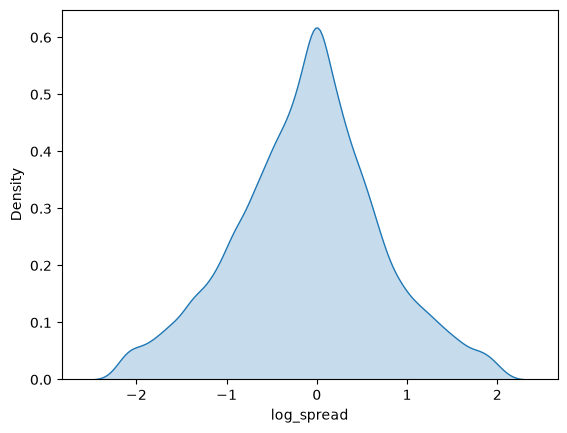

In [12]:
final_data = transfer_full[transfer_full.has_fee == 1].select_dtypes(exclude=["str"]).drop(columns=["has_fee",
                                                                                                "has_recent_appearances", 
                                                                                                "from_club_id", 
                                                                                                "to_club_id", 
                                                                                                "club_id_to", 
                                                                                                "club_id_from", 
                                                                                                "squad_size_from",
                                                                                                "foreigners_percentage_from",
                                                                                                "national_team_players_from",
                                                                                                "squad_size_to",
                                                                                                "average_age_to",
                                                                                                "foreigners_percentage_to",
                                                                                                "national_team_players_to",
                                                                                                "average_age_from",
                                                                                                "transfer_fee",
                                                                                                "market_value_in_eur",
                                                                                                "to_club_squad_size",
                                                                                                "from_club_squad_size",
                                                                                                "to_club_average_age",
                                                                                                "from_club_average_age",
                                                                                                "to_club_foreigners_pct",
                                                                                                "from_club_foreigners_pct",
                                                                                                "to_club_national_team_players",
                                                                                                "from_club_national_team_players"])
final_data = final_data[(final_data.log_spread < final_data.log_spread.quantile(0.98)) & (final_data.log_spread > final_data.log_spread.quantile(0.02))]
sns.kdeplot(data=final_data, x="log_spread", fill=True)

In [13]:
final_data["has_prior_paid_transfer"] = ((final_data.prev_transfer_fee != 0) & (final_data.prev_transfer_fee.notna())).astype("bool")

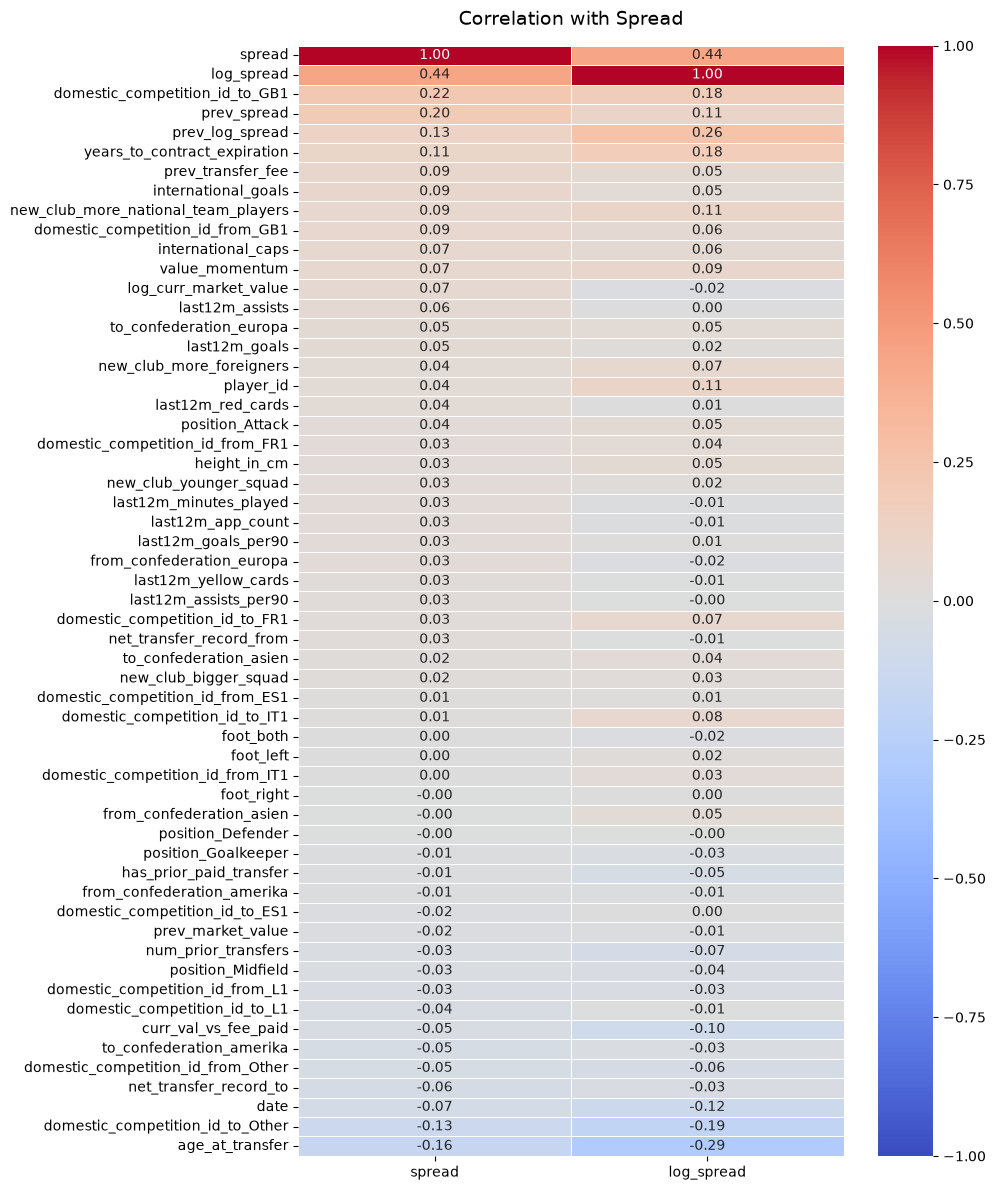

In [14]:
spread_corr = final_data.corr()[['spread', "log_spread"]].sort_values(by='spread', ascending=False)

# 2. Plot as a tall, narrow heatmap
plt.figure(figsize=(10, 12))
sns.heatmap(
    spread_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Correlation with Spread", fontsize=14, pad=15)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [15]:
#remove redundant columns
to_drop = ["prev_transfer_fee", "prev_market_value", "prev_spread", 
           "last12m_app_count", "last12m_yellow_cards", "last12m_red_cards", 
           "last12m_goals", "last12m_assists", "foot_left", "foot_right", 
           "new_club_bigger_squad", "new_club_younger_squad", "net_transfer_record_from"]
to_drop_for_linear_model = to_drop + ["curr_val_vs_fee_paid", "position_Goalkeeper", "domestic_competition_id_to_Other", "domestic_competition_id_from_Other"]

final_data["is_missing_value_momentum"] = final_data.value_momentum.isna()
final_data["is_missing_contract_exp"] = final_data.years_to_contract_expiration.isna()
final_data["is_missing_net_transfer_record_to"] = final_data.net_transfer_record_to.isna()

#final_data_linear = final_data.drop(columns=to_drop_for_linear_model).copy()
# final_data_linear.prev_log_spread = final_data_linear.prev_log_spread.replace(np.nan, 0)
# final_data_linear.value_momentum = final_data_linear.value_momentum.replace(np.nan, 0)
# final_data = final_data.drop(columns=to_drop).copy()


In [16]:
df_model = final_data.copy()
df_model = df_model.sort_values("date").reset_index(drop=True)

# Save player_id separately (keeps exact same index as X)
player_ids = (
    df_model["player_id"].copy()
    if "player_id" in df_model.columns
    else transfer_full.loc[df_model.index, "player_id"].copy()
)

# Target
y = df_model["log_spread"].astype(float)

# Drop IDs, targets, and redundant/noise columns
cols_to_drop = [
    "player_id", "from_club_id", "to_club_id", "club_id_from", "club_id_to",
    "date", "spread", "log_spread",
    "prev_transfer_fee", "prev_market_value", "prev_spread",
    "last12m_app_count", "last12m_goals", "last12m_assists",
    "last12m_yellow_cards", "last12m_red_cards",
    "net_transfer_record_from", "foot_left", "foot_right", "foot_both",
    "new_club_bigger_squad", "new_club_younger_squad",
]
X = df_model.drop(columns=[c for c in cols_to_drop if c in df_model.columns]).copy()

# Missingness flags
for col in ["years_to_contract_expiration", "value_momentum", "net_transfer_record_to"]:
    if col in X.columns:
        X[f"is_missing_{col}"] = X[col].isna().astype(float)

X = X.apply(pd.to_numeric, errors="coerce").astype(float)

# Sanity check
assert "player_id" not in X.columns, "player_id is still in X!"

# 5. Chronological 80/20 train-test split
split_idx = int(len(df_model) * 0.80)
X_train, X_test = X.iloc[:split_idx].copy(), X.iloc[split_idx:].copy()
y_train, y_test = y.iloc[:split_idx].copy(), y.iloc[split_idx:].copy()

cutoff_date = df_model["date"].iloc[split_idx]
print(f"Train rows: {len(X_train):,} | Test rows: {len(X_test):,} | Split date: {cutoff_date.date()}")
print(f"Total features: {X_train.shape[1]}")

Train rows: 12,608 | Test rows: 3,152 | Split date: 2024-12-19
Total features: 43


In [17]:

# Drop 1 reference dummy per one-hot group + curr_val_vs_fee_paid (near-identity) for linear models
linear_drop = ["curr_val_vs_fee_paid", "position_Goalkeeper", 
               "domestic_competition_id_to_Other", "domestic_competition_id_from_Other"]
linear_cols = [c for c in X_train.columns if c not in linear_drop]

# Zero-impute log-ratio history features; median-impute everything else
zero_impute_cols = [c for c in ["prev_log_spread", "value_momentum"] if c in linear_cols]
median_impute_cols = [c for c in linear_cols if c not in zero_impute_cols]

linear_preprocessor = ColumnTransformer(
    transformers=[
        ("zero_imp", SimpleImputer(strategy="constant", fill_value=0.0), zero_impute_cols),
        ("med_imp", SimpleImputer(strategy="median"), median_impute_cols),
    ]
)

tscv = TimeSeriesSplit(n_splits=5)

linear_models = {
    "Dummy (Median)": DummyRegressor(strategy="median"),
    "RidgeCV": RidgeCV(alphas=np.logspace(-2, 4, 25), cv=tscv),
    "ElasticNetCV": ElasticNetCV(l1_ratio=[0.1, 0.5, 0.9], alphas=np.logspace(-4, 1, 20), cv=tscv, max_iter=5000, random_state=42),
    "HuberRegressor": HuberRegressor(max_iter=500, alpha=1.0),
}

predictions = {}
fitted_models = {}

for name, estimator in linear_models.items():
    pipe = Pipeline([
        ("prep", linear_preprocessor),
        ("scaler", StandardScaler()),
        ("model", estimator),
    ])
    pipe.fit(X_train[linear_cols], y_train)
    predictions[name] = pipe.predict(X_test[linear_cols])
    fitted_models[name] = pipe
    print(f"Trained {name}")

Trained Dummy (Median)
Trained RidgeCV
Trained ElasticNetCV
Trained HuberRegressor


In [18]:
# 1. Scikit-learn tree models (always available)
# HistGradientBoosting handles NaNs natively
hgb = HistGradientBoostingRegressor(
    loss="absolute_error",
    max_depth=4,
    learning_rate=0.05,
    max_iter=300,
    min_samples_leaf=30,
    l2_regularization=5.0,
    random_state=42,
)
hgb.fit(X_train, y_train)
predictions["HistGradientBoosting (MAE)"] = hgb.predict(X_test)
fitted_models["HistGradientBoosting (MAE)"] = hgb
print("Trained HistGradientBoosting (MAE)")

# Random Forest (median imputation inside pipeline)
rf_pipe = Pipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        n_estimators=300,
        max_depth=10,
        min_samples_leaf=20,
        n_jobs=-1,
        random_state=42,
    )),
])
rf_pipe.fit(X_train, y_train)
predictions["RandomForest"] = rf_pipe.predict(X_test)
fitted_models["RandomForest"] = rf_pipe
print("Trained RandomForest")

# 2. LightGBM (handles NaNs natively)
lgbm = LGBMRegressor(
        objective="huber",
        n_estimators=400,
        learning_rate=0.03,
        max_depth=4,
        num_leaves=15,
        min_child_samples=30,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=5.0,
        random_state=42,
        verbose=-1,
    )
lgbm.fit(X_train, y_train)
predictions["LightGBM (Huber)"] = lgbm.predict(X_test)
fitted_models["LightGBM (Huber)"] = lgbm
print("Trained LightGBM (Huber)")

# 3. XGBoost (handles NaNs natively)
xgb = XGBRegressor(
        objective="reg:pseudohubererror",
        n_estimators=400,
        learning_rate=0.03,
        max_depth=4,
        min_child_weight=20,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=5.0,
        random_state=42,
        n_jobs=-1,
    )
xgb.fit(X_train, y_train)
predictions["XGBoost (Pseudo-Huber)"] = xgb.predict(X_test)
fitted_models["XGBoost (Pseudo-Huber)"] = xgb
print("Trained XGBoost (Pseudo-Huber)")

# 4. CatBoost (handles NaNs natively)
cb = CatBoostRegressor(
        loss_function="Huber:delta=1.0",
        iterations=500,
        learning_rate=0.04,
        depth=5,
        l2_leaf_reg=5.0,
        random_seed=42,
        verbose=0,
    )
cb.fit(X_train, y_train)
predictions["CatBoost (Huber)"] = cb.predict(X_test)
fitted_models["CatBoost (Huber)"] = cb
print("Trained CatBoost (Huber)")


Trained HistGradientBoosting (MAE)
Trained RandomForest
Trained LightGBM (Huber)
Trained XGBoost (Pseudo-Huber)
Trained CatBoost (Huber)


,Model,MAE (log_spread),RMSE (log_spread),R2,Median Fee % Error
0,XGBoost (Pseudo-Huber),0.5131,0.6578,0.2777,38.0146
1,LightGBM (Huber),0.5154,0.6608,0.2711,38.2135
2,HistGradientBoosting (MAE),0.5165,0.6646,0.2628,38.3896
3,CatBoost (Huber),0.5175,0.6633,0.2658,38.8570
4,Blend (30% Ridge + 70% LightGBM),0.5195,0.6655,0.2608,38.9423
5,RandomForest,0.5273,0.6788,0.2309,38.9926
6,HuberRegressor,0.5415,0.6932,0.1979,40.5729
7,RidgeCV,0.5427,0.6930,0.1985,40.6888
8,ElasticNetCV,0.5428,0.6939,0.1963,40.4348
9,Dummy (Median),0.6085,0.7965,-0.0590,46.6288


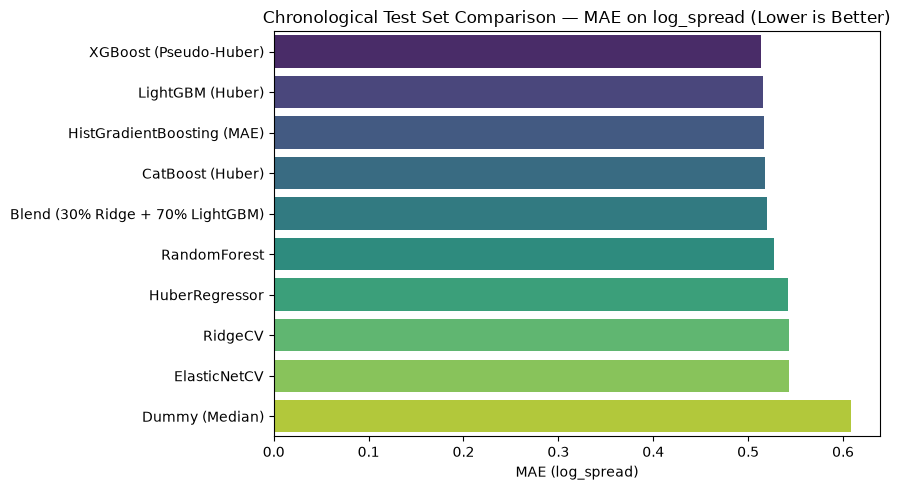

In [19]:
# Add a simple 30/70 blend of RidgeCV + best available GBDT
best_gbdt_name = next(
    (m for m in ["LightGBM (Huber)", "CatBoost (Huber)", "XGBoost (Pseudo-Huber)", "HistGradientBoosting (MAE)"] if m in predictions),
    None
)
if best_gbdt_name:
    predictions[f"Blend (30% Ridge + 70% {best_gbdt_name.split()[0]})"] = (
        0.3 * predictions["RidgeCV"] + 0.7 * predictions[best_gbdt_name]
    )

# Evaluate all models on the chronological test set
rows = []
actual_ratio = np.exp(y_test)

for name, y_pred in predictions.items():
    pred_ratio = np.exp(y_pred)
    median_pct_err = np.median(np.abs(pred_ratio - actual_ratio) / actual_ratio) * 100

    rows.append({
        "Model": name,
        "MAE (log_spread)": mean_absolute_error(y_test, y_pred),
        "RMSE (log_spread)": root_mean_squared_error(y_test, y_pred),
        "R2": r2_score(y_test, y_pred),
        "Median Fee % Error": median_pct_err,
    })

results_df = pd.DataFrame(rows).sort_values("MAE (log_spread)").reset_index(drop=True)
display(results_df.round(4))

# Plot Test MAE comparison
plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x="MAE (log_spread)", y="Model", hue="Model", palette="viridis", legend=False)
plt.title("Chronological Test Set Comparison — MAE on log_spread (Lower is Better)")
plt.xlabel("MAE (log_spread)")
plt.ylabel("")
plt.tight_layout()
plt.show()

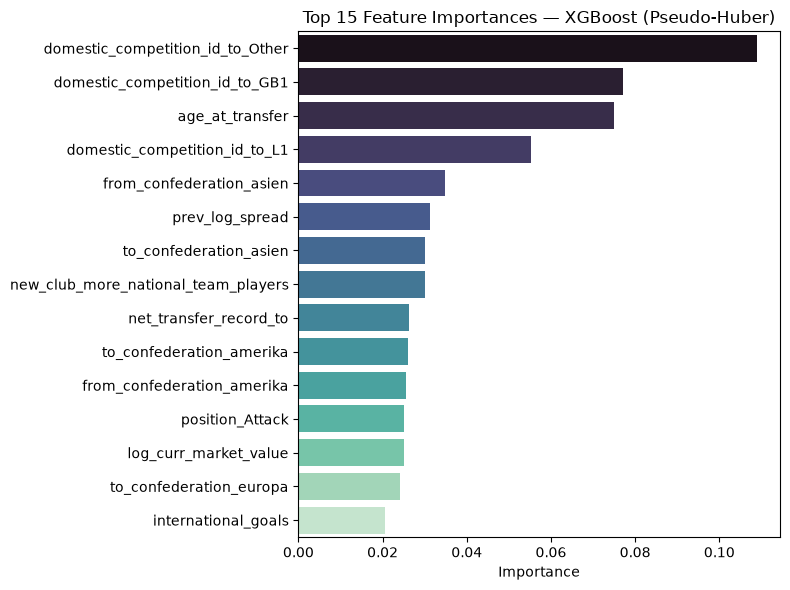

In [20]:
# Inspect feature importances from the best tree model
tree_candidates = [m for m in results_df["Model"] if m in fitted_models and m not in linear_models]
best_tree_name = tree_candidates[0]
best_tree = fitted_models[best_tree_name]

if best_tree_name == "RandomForest":
    importances = best_tree.named_steps["model"].feature_importances_
elif hasattr(best_tree, "feature_importances_"):
    importances = best_tree.feature_importances_
else:
    # Fallback to permutation importance for HistGradientBoosting
    from sklearn.inspection import permutation_importance
    perm = permutation_importance(best_tree, X_test, y_test, scoring="neg_mean_absolute_error", n_repeats=5, random_state=42)
    importances = perm.importances_mean

feat_imp = (
    pd.Series(importances, index=X_train.columns)
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(8, 6))
sns.barplot(x=feat_imp.values, y=feat_imp.index, hue=feat_imp.index, palette="mako", legend=False)
plt.title(f"Top 15 Feature Importances — {best_tree_name}")
plt.xlabel("Importance")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [21]:
actual_log_fee = y_test + X_test["log_curr_market_value"]
pred_log_fee = predictions["XGBoost (Pseudo-Huber)"] + X_test["log_curr_market_value"]
print("TM alone R2:", round(r2_score(actual_log_fee, X_test["log_curr_market_value"]), 4))
print("TM + XGBoost R2:", round(r2_score(actual_log_fee, pred_log_fee), 4))

TM alone R2: 0.738
TM + XGBoost R2: 0.8238


In [22]:
# Binary target: 1 if actual transfer fee > Transfermarkt value (premium), 0 otherwise
y_true_dir = (y_test.values > 0).astype(int)

spread_rows = []
for name, y_pred in predictions.items():
    y_pred_dir = (y_pred > 0).astype(int)
    spearman_r = spearmanr(y_test.values, y_pred).statistic

    spread_rows.append({
        "Model": name,
        "R2 (log_spread)": r2_score(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": root_mean_squared_error(y_test, y_pred),
        "Spearman r": spearman_r,
        "Dir. Accuracy": accuracy_score(y_true_dir, y_pred_dir),
        "ROC-AUC": roc_auc_score(y_true_dir, y_pred),
        "Precision": precision_score(y_true_dir, y_pred_dir, zero_division=0),
        "Recall": recall_score(y_true_dir, y_pred_dir, zero_division=0),
        "F1": f1_score(y_true_dir, y_pred_dir, zero_division=0),
    })

spread_metrics_df = pd.DataFrame(spread_rows).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
print(f"Base rate (actual Fee > TM Value): {y_true_dir.mean():.1%}")
display(spread_metrics_df.round(4))

Base rate (actual Fee > TM Value): 37.2%


C:\Users\marti\AppData\Local\Temp\ipykernel_25456\548565404.py:7: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_r = spearmanr(y_test.values, y_pred).statistic


,Model,R2 (log_spread),MAE,RMSE,Spearman r,Dir. Accuracy,ROC-AUC,Precision,Recall,F1
0,XGBoost (Pseudo-Huber),0.2777,0.5131,0.6578,0.5183,0.7113,0.7558,0.6646,0.4514,0.5376
1,LightGBM (Huber),0.2711,0.5154,0.6608,0.5136,0.7132,0.7540,0.6658,0.4590,0.5434
2,Blend (30% Ridge + 70% LightGBM),0.2608,0.5195,0.6655,0.5047,0.7091,0.7513,0.6620,0.4445,0.5319
3,HistGradientBoosting (MAE),0.2628,0.5165,0.6646,0.5059,0.7148,0.7509,0.6535,0.4957,0.5638
4,CatBoost (Huber),0.2658,0.5175,0.6633,0.5059,0.7113,0.7491,0.6594,0.4625,0.5436
5,RandomForest,0.2309,0.5273,0.6788,0.4734,0.7043,0.7286,0.6587,0.4249,0.5166
6,HuberRegressor,0.1979,0.5415,0.6932,0.4430,0.7002,0.7248,0.6254,0.4829,0.5450
7,RidgeCV,0.1985,0.5427,0.6930,0.4413,0.6957,0.7237,0.6279,0.4462,0.5217
8,ElasticNetCV,0.1963,0.5428,0.6939,0.4393,0.6973,0.7224,0.6313,0.4471,0.5235
9,Dummy (Median),-0.0590,0.6085,0.7965,NaN,0.6282,0.5000,0.0000,0.0000,0.0000


In [23]:
# Reconstruct actual Market Value and Final Transfer Fee in euros
tm_val = np.exp(X_test["log_curr_market_value"].values)
actual_log_fee = y_test.values + X_test["log_curr_market_value"].values
actual_fee = np.exp(actual_log_fee)

fee_rows = []

# Benchmark: predicting Final Fee = Transfermarkt Value (i.e., log_spread = 0)
all_eval = {"Transfermarkt Alone (spread=0)": np.zeros(len(y_test)), **predictions}

for name, y_pred in all_eval.items():
    pred_log_fee = y_pred + X_test["log_curr_market_value"].values
    pred_fee = np.exp(pred_log_fee)

    pct_err = np.abs(pred_fee - actual_fee) / actual_fee

    fee_rows.append({
        "Model": name,
        "R2 (log_fee)": r2_score(actual_log_fee, pred_log_fee),
        "R2 (EUR fee)": r2_score(actual_fee, pred_fee),
        "MAE (EUR M)": mean_absolute_error(actual_fee, pred_fee) / 1e6,
        "RMSE (EUR M)": root_mean_squared_error(actual_fee, pred_fee) / 1e6,
        "Median % Err": np.median(pct_err) * 100,
        "Within ±20%": (pct_err <= 0.20).mean() * 100,
        "Within ±30%": (pct_err <= 0.30).mean() * 100,
    })

fee_metrics_df = pd.DataFrame(fee_rows).sort_values("R2 (log_fee)", ascending=False).reset_index(drop=True)
display(fee_metrics_df.round(3))

,Model,R2 (log_fee),R2 (EUR fee),MAE (EUR M),RMSE (EUR M),Median % Err,Within ±20%,Within ±30%
0,XGBoost (Pseudo-Huber),0.824,0.862,1.665,3.722,38.015,25.825,39.530
1,LightGBM (Huber),0.822,0.862,1.675,3.717,38.213,26.079,38.737
2,CatBoost (Huber),0.821,0.862,1.681,3.718,38.857,26.015,39.594
3,HistGradientBoosting (MAE),0.820,0.868,1.659,3.635,38.390,26.079,39.467
4,Blend (30% Ridge + 70% LightGBM),0.820,0.860,1.680,3.749,38.942,25.603,39.118
5,RandomForest,0.812,0.857,1.712,3.791,38.993,25.698,39.340
6,RidgeCV,0.805,0.819,1.818,4.262,40.689,25.317,37.278
7,HuberRegressor,0.804,0.815,1.825,4.311,40.573,25.349,37.754
8,ElasticNetCV,0.804,0.821,1.812,4.240,40.435,25.317,37.754
9,Dummy (Median),0.742,0.832,1.889,4.103,46.629,25.190,35.057


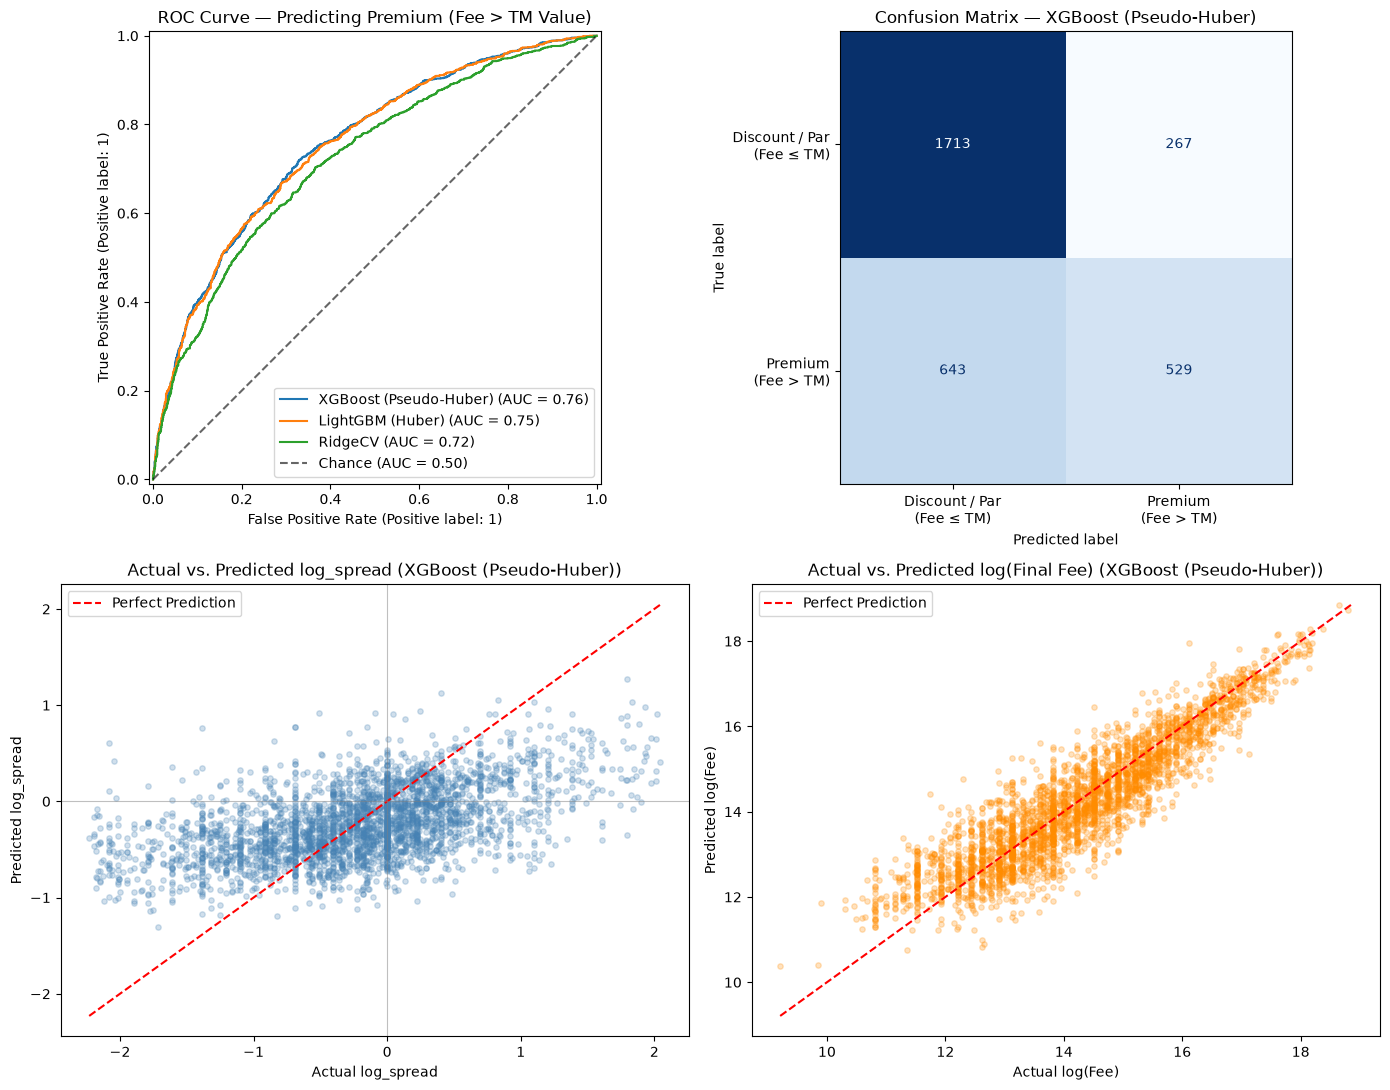

In [24]:
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay

best_model_name = results_df.iloc[0]["Model"]
best_pred_spread = predictions[best_model_name]
best_pred_log_fee = best_pred_spread + X_test["log_curr_market_value"].values

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# 1. ROC Curves (Premium vs. Discount: Fee > TM Value)
ax = axes[0, 0]
models_to_plot = [m for m in [best_model_name, "LightGBM (Huber)", "RidgeCV"] if m in predictions]
for m in dict.fromkeys(models_to_plot):  # preserve order, remove duplicates
    RocCurveDisplay.from_predictions(y_true_dir, predictions[m], name=m, ax=ax)
ax.plot([0, 1], [0, 1], "k--", alpha=0.6, label="Chance (AUC = 0.50)")
ax.set_title("ROC Curve — Predicting Premium (Fee > TM Value)")
ax.legend(loc="lower right")

# 2. Confusion Matrix for Best Model
ax = axes[0, 1]
ConfusionMatrixDisplay.from_predictions(
    y_true_dir,
    (best_pred_spread > 0).astype(int),
    display_labels=["Discount / Par\n(Fee ≤ TM)", "Premium\n(Fee > TM)"],
    cmap="Blues",
    ax=ax,
    colorbar=False,
)
ax.set_title(f"Confusion Matrix — {best_model_name}")

# 3. Actual vs. Predicted log_spread
ax = axes[1, 0]
ax.scatter(y_test, best_pred_spread, alpha=0.25, s=15, color="steelblue")
lims = [min(y_test.min(), best_pred_spread.min()), max(y_test.max(), best_pred_spread.max())]
ax.plot(lims, lims, "r--", lw=1.5, label="Perfect Prediction")
ax.axhline(0, color="gray", lw=0.8, alpha=0.5)
ax.axvline(0, color="gray", lw=0.8, alpha=0.5)
ax.set_title(f"Actual vs. Predicted log_spread ({best_model_name})")
ax.set_xlabel("Actual log_spread")
ax.set_ylabel("Predicted log_spread")
ax.legend()

# 4. Actual vs. Predicted Final Fee (Log Scale)
ax = axes[1, 1]
ax.scatter(actual_log_fee, best_pred_log_fee, alpha=0.25, s=15, color="darkorange")
fee_lims = [min(actual_log_fee.min(), best_pred_log_fee.min()), max(actual_log_fee.max(), best_pred_log_fee.max())]
ax.plot(fee_lims, fee_lims, "r--", lw=1.5, label="Perfect Prediction")
ax.set_title(f"Actual vs. Predicted log(Final Fee) ({best_model_name})")
ax.set_xlabel("Actual log(Fee)")
ax.set_ylabel("Predicted log(Fee)")
ax.legend()

plt.tight_layout()
plt.show()

,Count,TM_Median_Pct_Err,Model_Median_Pct_Err,TM_Within_30pct,Model_Within_30pct
tier,,,,,
< €1M,1252,60.00,47.08,28.67,31.71
€1M – €5M,1101,50.00,38.26,35.60,38.24
€5M – €15M,574,36.54,31.35,42.33,47.74
> €15M,225,20.63,22.06,62.22,68.44


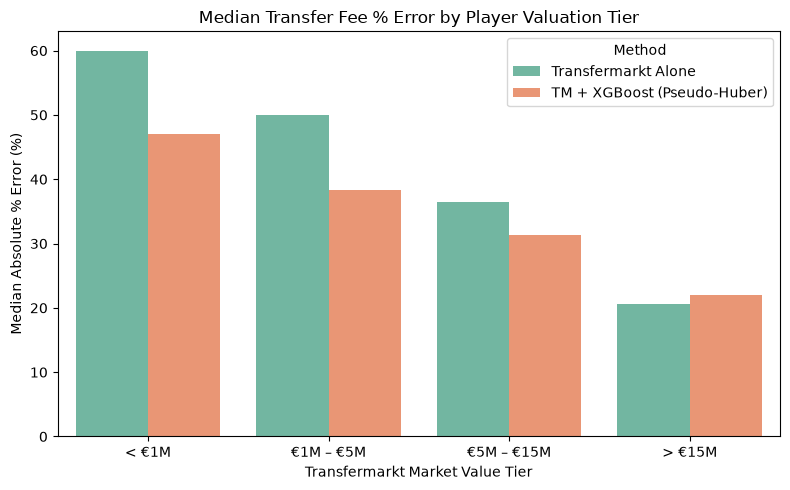

In [25]:
tier_df = pd.DataFrame({
    "tm_val": tm_val,
    "actual_fee": actual_fee,
    "pred_fee": np.exp(best_pred_log_fee),
})

tier_df["tm_pct_err"] = np.abs(tier_df["tm_val"] - tier_df["actual_fee"]) / tier_df["actual_fee"] * 100
tier_df["model_pct_err"] = np.abs(tier_df["pred_fee"] - tier_df["actual_fee"]) / tier_df["actual_fee"] * 100

bins = [0, 1e6, 5e6, 15e6, np.inf]
labels = ["< €1M", "€1M – €5M", "€5M – €15M", "> €15M"]
tier_df["tier"] = pd.cut(tier_df["tm_val"], bins=bins, labels=labels)

summary = tier_df.groupby("tier", observed=False).agg(
    Count=("actual_fee", "count"),
    TM_Median_Pct_Err=("tm_pct_err", "median"),
    Model_Median_Pct_Err=("model_pct_err", "median"),
    TM_Within_30pct=("tm_pct_err", lambda s: (s <= 30).mean() * 100),
    Model_Within_30pct=("model_pct_err", lambda s: (s <= 30).mean() * 100),
)
display(summary.round(2))

# Side-by-side bar chart of Median % Error by Market Value Tier
plot_df = summary[["TM_Median_Pct_Err", "Model_Median_Pct_Err"]].reset_index().melt(
    id_vars="tier", var_name="Method", value_name="Median Fee % Error"
)
plot_df["Method"] = plot_df["Method"].replace({
    "TM_Median_Pct_Err": "Transfermarkt Alone",
    "Model_Median_Pct_Err": f"TM + {best_model_name}",
})

plt.figure(figsize=(8, 5))
sns.barplot(data=plot_df, x="tier", y="Median Fee % Error", hue="Method", palette="Set2")
plt.title("Median Transfer Fee % Error by Player Valuation Tier")
plt.xlabel("Transfermarkt Market Value Tier")
plt.ylabel("Median Absolute % Error (%)")
plt.tight_layout()
plt.show()

In [26]:
new_df = transfer_full.merge(pd.read_csv(".\\transfermarkt data\\players.csv")[["player_id", "first_name", "last_name", "name"]],how="left", on="player_id")
new_df.head()

,player_id,date,transfer_season,from_club_id,to_club_id,transfer_fee,market_value_in_eur,has_fee,num_prior_transfers,prev_transfer_fee,...,new_club_bigger_squad,new_club_younger_squad,new_club_more_foreigners,new_club_more_national_team_players,log_curr_market_value,value_momentum,curr_val_vs_fee_paid,first_name,last_name,name
0,2989,2006-07-01,06/07,27,41,2500000.0,3000000.0,1,2,NaN,...,False,True,True,False,14.914123,NaN,NaN,Paolo,Guerrero,Paolo Guerrero
1,2989,2012-07-15,12/13,41,199,3500000.0,6000000.0,1,3,2500000.0,...,True,False,False,False,15.607270,0.693147,0.875469,Paolo,Guerrero,Paolo Guerrero
2,3333,2008-08-29,08/09,762,405,15000000.0,8750000.0,1,3,7400000.0,...,True,False,True,True,15.984564,NaN,0.167574,James,Milner,James Milner
3,3333,2010-08-17,10/11,405,281,22000000.0,20000000.0,1,4,15000000.0,...,True,True,False,True,16.811243,0.826679,0.287682,James,Milner,James Milner
4,4391,2007-07-01,07/08,306,1090,3000000.0,800000.0,1,2,NaN,...,True,False,False,True,13.592367,NaN,NaN,Boy,Waterman,Boy Waterman


In [27]:
# Define player valuation tiers based on current Transfermarkt value (€)
tm_all = np.exp(X["log_curr_market_value"])
bins = [0, 2e6, 10e6, 25e6, np.inf]
labels = ["Small (< €2M)", "Mid (€2M – €10M)", "Starter (€10M – €25M)", "Star (> €25M)"]
tiers = pd.cut(tm_all, bins=bins, labels=labels)

def make_xgb(n_rows):
    """Slightly shallower/more regularized trees when a tier has fewer rows."""
    return XGBRegressor(
        objective="reg:pseudohubererror",
        n_estimators=300 if n_rows < 1500 else 400,
        learning_rate=0.03,
        max_depth=3 if n_rows < 1500 else 4,
        min_child_weight=10 if n_rows < 1500 else 20,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=5.0,
        random_state=42,
        n_jobs=-1,
    )

# Fit a clean Global XGBoost on the full 80/20 split for apples-to-apples comparison
global_xgb = make_xgb(len(X_train))
global_xgb.fit(X_train, y_train)

tier_results = []

for tier_name in labels:
    # Restrict to this tier's rows inside the SAME global train/test split (zero leakage)
    tr_mask = (tiers.loc[X_train.index] == tier_name)
    te_mask = (tiers.loc[X_test.index] == tier_name)

    X_tr_t, y_tr_t = X_train[tr_mask], y_train[tr_mask]
    X_te_t, y_te_t = X_test[te_mask], y_test[te_mask]

    # Train Tier-Specific XGBoost
    tier_xgb = make_xgb(len(X_tr_t))
    tier_xgb.fit(X_tr_t, y_tr_t)

    pred_tier = tier_xgb.predict(X_te_t)
    pred_global = global_xgb.predict(X_te_t)

    # Convert to actual and predicted fees (€)
    tm_te = np.exp(X_te_t["log_curr_market_value"].values)
    actual_fee = np.exp(X_te_t["log_curr_market_value"].values + y_te_t.values)
    fee_tier = np.exp(X_te_t["log_curr_market_value"].values + pred_tier)
    fee_global = np.exp(X_te_t["log_curr_market_value"].values + pred_global)

    tm_med_err = np.median(np.abs(tm_te - actual_fee) / actual_fee) * 100
    tier_med_err = np.median(np.abs(fee_tier - actual_fee) / actual_fee) * 100
    glob_med_err = np.median(np.abs(fee_global - actual_fee) / actual_fee) * 100

    y_dir = (y_te_t.values > 0).astype(int)

    tier_results.append({
        "Tier": tier_name,
        "N_Train": len(X_tr_t),
        "N_Test": len(X_te_t),
        "Target Std": y_te_t.std(),
        "TM Med % Err": tm_med_err,
        "Tier-XGB R2": r2_score(y_te_t, pred_tier),
        "Tier-XGB MAE": mean_absolute_error(y_te_t, pred_tier),
        "Tier-XGB AUC": roc_auc_score(y_dir, pred_tier),
        "Tier-XGB Med % Err": tier_med_err,
        "Global-XGB R2": r2_score(y_te_t, pred_global),
        "Global-XGB MAE": mean_absolute_error(y_te_t, pred_global),
        "Global-XGB Med % Err": glob_med_err,
        "Lift vs TM (pp)": tm_med_err - glob_med_err,
    })

tier_comp_df = pd.DataFrame(tier_results)
display(tier_comp_df.round(3))

,Tier,N_Train,N_Test,Target Std,TM Med % Err,Tier-XGB R2,Tier-XGB MAE,Tier-XGB AUC,Tier-XGB Med % Err,Global-XGB R2,Global-XGB MAE,Global-XGB Med % Err,Lift vs TM (pp)
0,Small (< €2M),7252,1753,0.864,58.333,0.279,0.587,0.758,44.994,0.281,0.584,45.393,12.940
1,Mid (€2M – €10M),3704,986,0.690,41.295,0.221,0.477,0.738,37.012,0.262,0.467,36.696,4.599
2,Starter (€10M – €25M),1161,289,0.516,29.412,0.265,0.339,0.761,25.004,0.256,0.333,25.276,4.136
3,Star (> €25M),491,124,0.434,19.327,0.068,0.299,0.637,20.592,0.117,0.290,21.395,-2.067


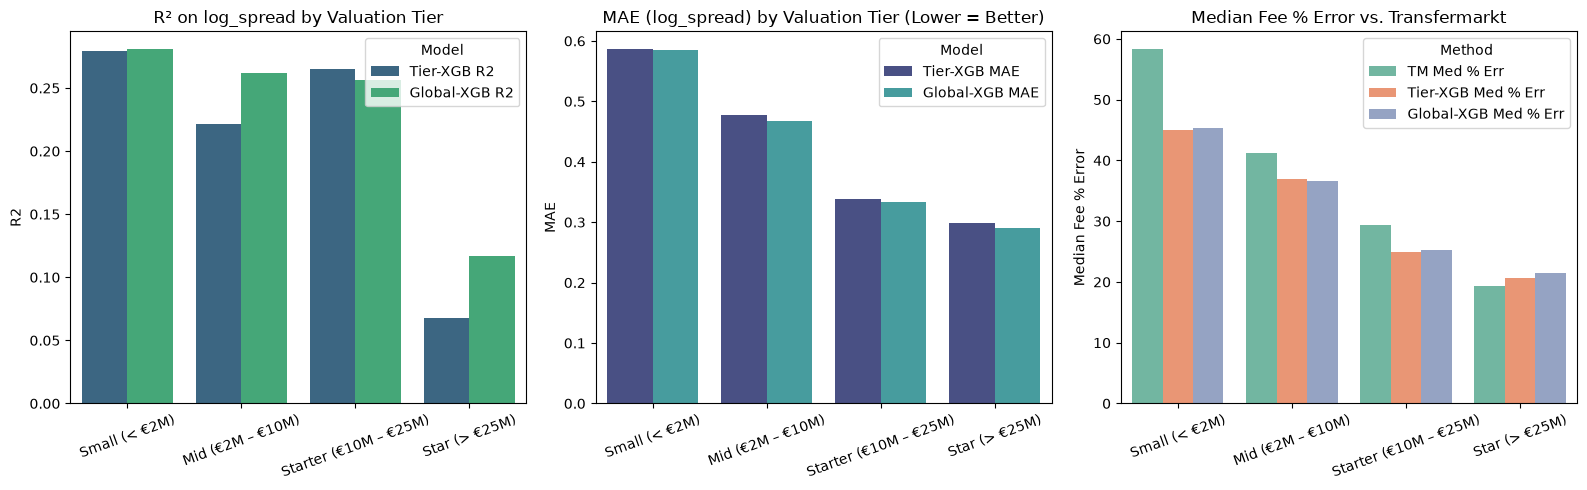

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. R2 on log_spread by Tier (Tier-Specific vs. Global)
r2_plot = tier_comp_df[["Tier", "Tier-XGB R2", "Global-XGB R2"]].melt(
    id_vars="Tier", var_name="Model", value_name="R2"
)
sns.barplot(data=r2_plot, x="Tier", y="R2", hue="Model", ax=axes[0], palette="viridis")
axes[0].set_title("R² on log_spread by Valuation Tier")
axes[0].tick_params(axis="x", rotation=20)
axes[0].set_xlabel("")

# 2. MAE on log_spread by Tier
mae_plot = tier_comp_df[["Tier", "Tier-XGB MAE", "Global-XGB MAE"]].melt(
    id_vars="Tier", var_name="Model", value_name="MAE"
)
sns.barplot(data=mae_plot, x="Tier", y="MAE", hue="Model", ax=axes[1], palette="mako")
axes[1].set_title("MAE (log_spread) by Valuation Tier (Lower = Better)")
axes[1].tick_params(axis="x", rotation=20)
axes[1].set_xlabel("")

# 3. Median Fee % Error: Transfermarkt Alone vs. Tier-XGB vs. Global-XGB
err_plot = tier_comp_df[["Tier", "TM Med % Err", "Tier-XGB Med % Err", "Global-XGB Med % Err"]].melt(
    id_vars="Tier", var_name="Method", value_name="Median Fee % Error"
)
sns.barplot(data=err_plot, x="Tier", y="Median Fee % Error", hue="Method", ax=axes[2], palette="Set2")
axes[2].set_title("Median Fee % Error vs. Transfermarkt")
axes[2].tick_params(axis="x", rotation=20)
axes[2].set_xlabel("")

plt.tight_layout()
plt.show()

,Model,R2 (log Fee),R2 (EUR Fee),MAE (€M),RMSE (€M),Median % Error,Within ±20% (%),Within ±30% (%)
0,XGBoost (Pseudo-Huber),0.824,0.862,1.665,3.722,38.015,25.825,39.530
1,LightGBM (Huber),0.822,0.862,1.675,3.717,38.213,26.079,38.737
2,CatBoost (Huber),0.821,0.862,1.681,3.718,38.857,26.015,39.594
3,HistGradientBoosting (MAE),0.820,0.868,1.659,3.635,38.390,26.079,39.467
4,Blend (30% Ridge + 70% LightGBM),0.820,0.860,1.680,3.749,38.942,25.603,39.118
5,RandomForest,0.812,0.857,1.712,3.791,38.993,25.698,39.340
6,RidgeCV,0.805,0.819,1.818,4.262,40.689,25.317,37.278
7,HuberRegressor,0.804,0.815,1.825,4.311,40.573,25.349,37.754
8,ElasticNetCV,0.804,0.821,1.812,4.240,40.435,25.317,37.754
9,Dummy (Median),0.742,0.832,1.889,4.103,46.629,25.190,35.057


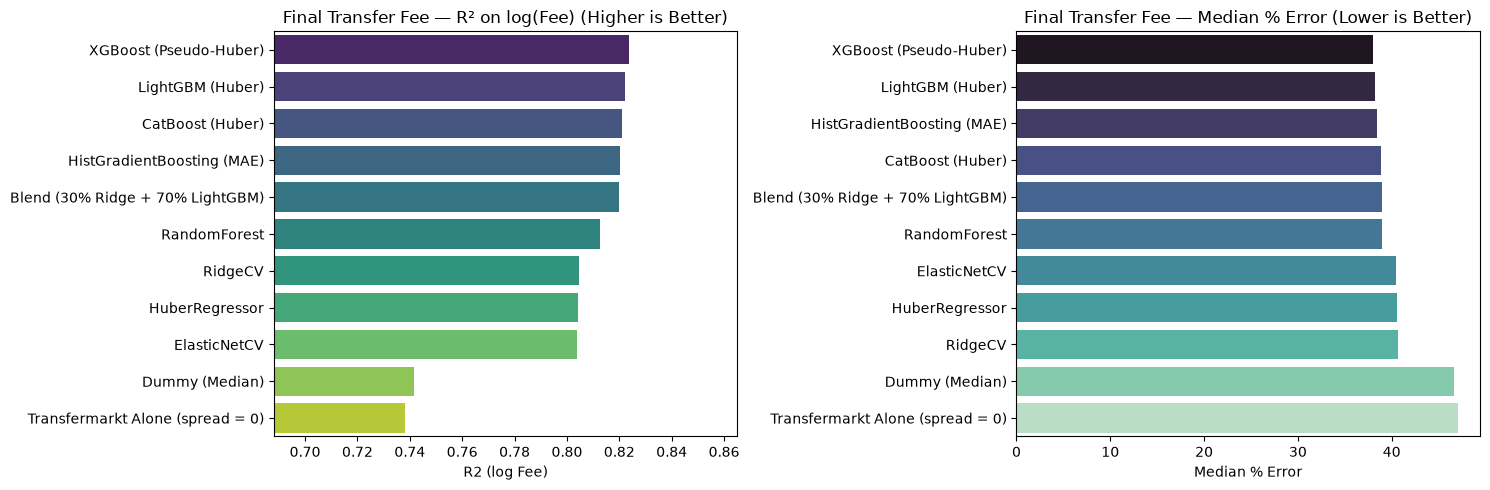

In [29]:
# 1. Recover Market Value (€) and Actual Final Fee (€) for X_test
if "log_curr_market_value" in X_test.columns:
    log_mv_test = X_test["log_curr_market_value"].values
    tm_val_test = np.exp(log_mv_test)
else:
    tm_val_test = transfer_full.loc[X_test.index, "market_value_in_eur"].values
    log_mv_test = np.log(tm_val_test)

actual_log_fee = log_mv_test + y_test.values
actual_fee = np.exp(actual_log_fee)

# 2. Include "Transfermarkt Alone" (predicted log_spread = 0) as the benchmark
all_preds = {"Transfermarkt Alone (spread = 0)": np.zeros(len(y_test)), **predictions}

fee_rows = []
for name, pred_log_spread in all_preds.items():
    pred_log_fee = log_mv_test + pred_log_spread
    pred_fee = np.exp(pred_log_fee)

    abs_err_eur = np.abs(pred_fee - actual_fee)
    pct_err = abs_err_eur / actual_fee

    fee_rows.append({
        "Model": name,
        "R2 (log Fee)": r2_score(actual_log_fee, pred_log_fee),
        "R2 (EUR Fee)": r2_score(actual_fee, pred_fee),
        "MAE (€M)": mean_absolute_error(actual_fee, pred_fee) / 1e6,
        "RMSE (€M)": root_mean_squared_error(actual_fee, pred_fee) / 1e6,
        "Median % Error": np.median(pct_err) * 100,
        "Within ±20% (%)": (pct_err <= 0.20).mean() * 100,
        "Within ±30% (%)": (pct_err <= 0.30).mean() * 100,
    })

fee_comparison_df = (
    pd.DataFrame(fee_rows)
    .sort_values("R2 (log Fee)", ascending=False)
    .reset_index(drop=True)
)

display(fee_comparison_df.round(3))

# 3. Visual comparison: R2 (log Fee) and Median % Error
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(
    data=fee_comparison_df, x="R2 (log Fee)", y="Model",
    hue="Model", palette="viridis", legend=False, ax=axes[0]
)
axes[0].set_title("Final Transfer Fee — R² on log(Fee) (Higher is Better)")
axes[0].set_xlim(left=max(0, fee_comparison_df["R2 (log Fee)"].min() - 0.05))
axes[0].set_ylabel("")

sns.barplot(
    data=fee_comparison_df.sort_values("Median % Error"), x="Median % Error", y="Model",
    hue="Model", palette="mako", legend=False, ax=axes[1]
)
axes[1].set_title("Final Transfer Fee — Median % Error (Lower is Better)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

In [32]:
import os

# Pick the best model by R2 on log(Fee) (excluding the TM benchmark)
best_model_name = fee_comparison_df.loc[
    fee_comparison_df["Model"] != "Transfermarkt Alone (spread = 0)", "Model"
].iloc[0]
best_pred_spread = predictions[best_model_name]

# Build test-set evaluation table using transfer_full metadata
meta_cols = ["player_id", "date", "transfer_season", "name_from", "name_to", "transfer_fee", "market_value_in_eur"]

# Handle both original index (cross-sectional split) and reset index (if df_model was sorted & reset)
if set(X_test.index).issubset(set(transfer_full.index)):
    test_players = transfer_full.loc[X_test.index, meta_cols].copy()
else:
    test_players = df_model.loc[X_test.index, ["player_id", "date"]].merge(
        transfer_full[meta_cols], on=["player_id", "date"], how="left"
    )

# Attach player names from players.csv if present
players_path = r".\transfermarkt data\players.csv"
if os.path.exists(players_path):
    players_df = pd.read_csv(players_path)
    name_col = "name" if "name" in players_df.columns else [c for c in players_df.columns if "name" in c.lower()][0]
    test_players = test_players.merge(
        players_df[["player_id", name_col]].drop_duplicates("player_id"),
        on="player_id", how="left"
    ).rename(columns={name_col: "Player"})
else:
    test_players["Player"] = "ID_" + test_players["player_id"].astype(str)

# Compute predicted fee and percentage errors
test_players["TM_Val (€M)"] = test_players["market_value_in_eur"] / 1e6
test_players["Pred_Fee (€M)"] = (test_players["market_value_in_eur"] * np.exp(best_pred_spread)) / 1e6
test_players["Actual_Fee (€M)"] = test_players["transfer_fee"] / 1e6

test_players["TM_Err (%)"] = np.abs(test_players["TM_Val (€M)"] - test_players["Actual_Fee (€M)"]) / test_players["Actual_Fee (€M)"] * 100
test_players["Model_Err (%)"] = np.abs(test_players["Pred_Fee (€M)"] - test_players["Actual_Fee (€M)"]) / test_players["Actual_Fee (€M)"] * 100
test_players["Beat_TM"] = test_players["Model_Err (%)"] < test_players["TM_Err (%)"]

show_cols = [
    "Player", "transfer_season", "name_from", "name_to",
    "TM_Val (€M)", "Pred_Fee (€M)", "Actual_Fee (€M)",
    "TM_Err (%)", "Model_Err (%)", "Beat_TM"
]

print(f"Best model evaluated: {best_model_name}")
print(f"Overall test set — Model beats Transfermarkt on {test_players['Beat_TM'].mean():.1%} of transfers\n")

# Table A: Top 15 biggest out-of-sample transfers in X_test
top15_test = test_players.sort_values("Actual_Fee (€M)", ascending=False).head(15)
print("--- Top 15 Biggest Transfers in X_test (Out-of-Sample) ---")
display(top15_test[show_cols].round(2).reset_index(drop=True))

mid15test = test_players[test_players["Actual_Fee (€M)"].between(1, 10)].sample(15, random_state=42).sort_values("Actual_Fee (€M)", ascending=False)
print("--- Mid 15 Transfers in X_test (Out-of-Sample) ---")
display(mid15test[show_cols].round(2).reset_index(drop=True))

# Table B: Random sample of 10 other out-of-sample transfers in X_test
sample10_test = test_players.sample(10, random_state=42).sort_values("Actual_Fee (€M)", ascending=False)
print("--- Random Sample of 10 Transfers in X_test (Out-of-Sample) ---")
display(sample10_test[show_cols].round(2).reset_index(drop=True))

Best model evaluated: XGBoost (Pseudo-Huber)
Overall test set — Model beats Transfermarkt on 59.7% of transfers

--- Top 15 Biggest Transfers in X_test (Out-of-Sample) ---


,Player,transfer_season,name_from,name_to,TM_Val (€M),Pred_Fee (€M),Actual_Fee (€M),TM_Err (%),Model_Err (%),Beat_TM
0,Alexander Isak,25/26,Newcastle United,Liverpool FC,120.0,137.59,145.0,17.24,5.11,True
1,Florian Wirtz,25/26,Bayer 04 Leverkusen,Liverpool FC,140.0,154.76,125.0,12.00,23.81,False
2,Hugo Ekitiké,25/26,Eintracht Frankfurt,Liverpool FC,75.0,87.00,95.0,21.05,8.42,True
3,Anthony Gordon,26/27,Newcastle United,FC Barcelona,65.0,63.51,80.0,18.75,20.61,False
4,Khvicha Kvaratskhelia,24/25,SSC Napoli,Paris Saint-Germain,85.0,79.52,80.0,6.25,0.60,True
5,Jhon Durán,24/25,Aston Villa,Al-Nassr Football Club,40.0,53.47,77.0,48.05,30.55,True
6,Benjamin Sesko,25/26,RB Leipzig,Manchester United,70.0,86.52,76.5,8.50,13.10,False
7,Bryan Mbeumo,25/26,Brentford FC,Manchester United,55.0,52.99,75.0,26.67,29.35,False
8,Nick Woltemade,25/26,VfB Stuttgart,Newcastle United,30.0,34.84,75.0,60.00,53.55,True
9,Omar Marmoush,24/25,Eintracht Frankfurt,Manchester City,60.0,58.74,75.0,20.00,21.68,False


--- Mid 15 Transfers in X_test (Out-of-Sample) ---


,Player,transfer_season,name_from,name_to,TM_Val (€M),Pred_Fee (€M),Actual_Fee (€M),TM_Err (%),Model_Err (%),Beat_TM
0,Sebastian Szymanski,25/26,Fenerbahce,Stade Rennais FC,12.00,8.20,9.50,26.32,13.71,True
1,Weslley Patati,25/26,NaN,AZ Alkmaar,2.50,2.25,7.30,65.75,69.22,False
2,Alerrandro,24/25,Red Bull Bragantino,PFK CSKA Moskva,4.00,3.04,4.20,4.76,27.62,False
3,Max Finkgräfe,25/26,1.FC Köln,RB Leipzig,4.00,3.80,4.00,0.00,4.93,False
4,Juan Musso,25/26,Atalanta BC,Atlético de Madrid,3.50,3.03,3.00,16.67,0.92,True
5,Mohamed Al-Thani,25/26,Al-Hazem Sport Club,Al-Qadsiah Saudi Football Club,0.90,1.71,2.55,64.71,32.94,True
6,Alan Virginius,25/26,LOSC Lille,BSC Young Boys,3.00,2.81,2.50,20.00,12.26,True
7,Antoine Bernede,25/26,Football Club Lausanne-Sport,Hellas Verona,2.50,2.01,2.00,25.00,0.68,True
8,Nesta Elphege,25/26,NaN,Parma Calcio 1913,0.50,0.66,2.00,75.00,66.87,True
9,Moisés,25/26,Fortaleza Esporte Clube,Santos Futebol Clube,2.50,2.14,2.00,25.00,6.81,True


--- Random Sample of 10 Transfers in X_test (Out-of-Sample) ---


,Player,transfer_season,name_from,name_to,TM_Val (€M),Pred_Fee (€M),Actual_Fee (€M),TM_Err (%),Model_Err (%),Beat_TM
0,Rocco Reitz,26/27,Borussia Mönchengladbach,RB Leipzig,20.0,14.40,20.00,0.00,28.02,False
1,Edon Zhegrova,25/26,LOSC Lille,Juventus FC,25.0,20.94,15.50,61.29,35.12,True
2,Luka Vuskovic,25/26,HNK Hajduk Split,Tottenham Hotspur,12.0,17.87,11.00,9.09,62.46,False
3,Tobías Ramírez,25/26,Asociación Atlética Argentinos Juniors,Club Atlético River Plate,2.5,3.17,4.30,41.86,26.26,True
4,Souleymane Faye,25/26,NaN,Granada CF,0.5,0.97,3.60,86.11,73.18,True
5,Jemmes,25/26,Mirasol Futebol Clube,Fluminense Football Club,1.5,1.39,3.60,58.33,61.49,False
6,Vaclav Sejk,25/26,SC Heerenveen,"SK Sigma Olomouc, a.s.",0.9,1.10,1.80,50.00,38.68,True
7,Redouane Berkane,25/26,NaN,NaN,0.8,0.66,0.65,23.08,0.99,True
8,Noel Buck,24/25,New England Revolution,San Jose Earthquakes,2.0,1.73,0.53,277.36,226.68,True
9,Iyad Mohamed,24/25,NaN,Casa Pia AC,0.6,0.35,0.10,500.00,248.95,True


In [33]:
test_players[show_cols]

,Player,transfer_season,name_from,name_to,TM_Val (€M),Pred_Fee (€M),Actual_Fee (€M),TM_Err (%),Model_Err (%),Beat_TM
0,Lukas MacNaughton,24/25,Nashville SC,D.C. United,1.500,0.696625,0.192,681.250000,262.825766,True
1,Elias Manoel,24/25,Red Bull New York,Real Salt Lake,2.000,1.451174,0.671,198.062593,116.270364,True
2,Anderson Julio,24/25,Real Salt Lake,FC Dallas,3.000,1.475139,0.384,681.250000,284.150725,True
3,Earl Edwards Jr.,24/25,New England Revolution,San Jose Earthquakes,0.125,0.074839,0.144,13.194444,48.028232,False
4,Jusuf Gazibegovic,24/25,Sportklub Puntigamer Sturm Graz,1.FC Köln,5.000,2.909208,2.000,150.000000,45.460412,True
...,...,...,...,...,...,...,...,...,...,...
3147,Dastan Satpaev,26/27,NaN,Chelsea FC,3.000,5.341203,2.400,25.000000,122.550139,False
3148,Kauã Prates,26/27,Cruzeiro Esporte Clube,Borussia Dortmund,10.000,10.946122,7.000,42.857143,56.373177,False
3149,Bruninho,26/27,Clube Atlético Paranaense,FC Shakhtar Donetsk,7.000,7.831657,11.000,36.363636,28.803118,True
3150,Saba Kharebashvili,26/27,NaN,Basaksehir FK,2.500,2.814714,2.500,0.000000,12.588561,False


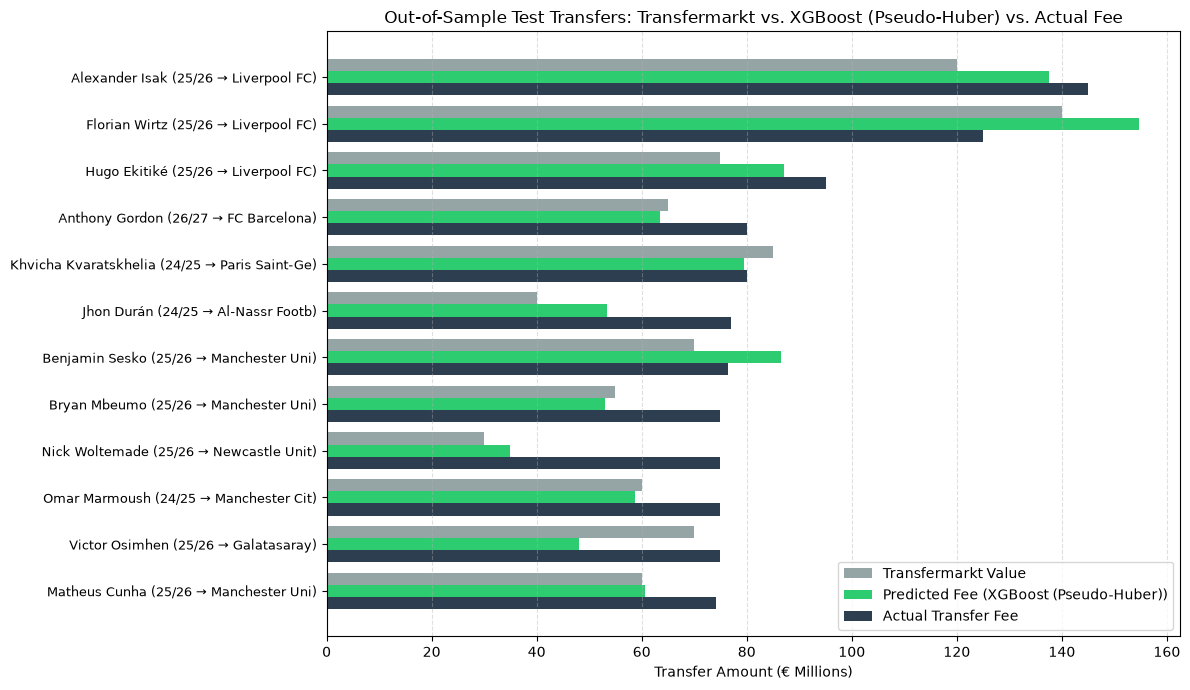

In [34]:
plot_df = top15_test.head(12).iloc[::-1].copy()
labels = (
    plot_df["Player"].fillna("Unknown")
    + " (" + plot_df["transfer_season"].astype(str)
    + " → " + plot_df["name_to"].fillna("Unknown").str.slice(0, 14) + ")"
)

y_pos = np.arange(len(plot_df))
h = 0.26

plt.figure(figsize=(12, 7))
plt.barh(y_pos + h, plot_df["TM_Val (€M)"], height=h, label="Transfermarkt Value", color="#95a5a6")
plt.barh(y_pos, plot_df["Pred_Fee (€M)"], height=h, label=f"Predicted Fee ({best_model_name})", color="#2ecc71")
plt.barh(y_pos - h, plot_df["Actual_Fee (€M)"], height=h, label="Actual Transfer Fee", color="#2c3e50")

plt.yticks(y_pos, labels, fontsize=9)
plt.xlabel("Transfer Amount (€ Millions)")
plt.title(f"Out-of-Sample Test Transfers: Transfermarkt vs. {best_model_name} vs. Actual Fee")
plt.legend()
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()